# Lumen · Relevance and crawler audit

A reproducible experiment using the same application modules as the running project. Run all cells in order. Demonstration data and fixed corpora are not evidence of production performance.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'app').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Graded relevance judgments

Define relevance before scoring models. Three grades permit nDCG to distinguish the best document from merely related results.

In [2]:
import json,math
from app.domain.ranking import Index
docs=[dict(id=str(i+1),**d) for i,d in enumerate(json.loads((ROOT/'data/corpus.json').read_text()))]
index=Index(docs)
judgments={
 'bm25 ranking':{'2':3,'12':2,'1':1},
 'web crawler robots':{'3':3},
 'fraud detection':{'8':3,'4':1},
 'phrase queries':{'11':3,'1':1},
 'database indexes':{'6':3,'1':1},
 'retrieval augmented generation':{'5':3,'7':1},
 'machine learning evaluation':{'4':3,'8':1},
 'distributed caching latency':{'9':3},
}
display(pd.DataFrame([{'query':q,'graded_relevance':r} for q,r in judgments.items()]))

,query,graded_relevance
0,bm25 ranking,"{'2': 3, '12': 2, '1': 1}"
1,web crawler robots,{'3': 3}
2,fraud detection,"{'8': 3, '4': 1}"
3,phrase queries,"{'11': 3, '1': 1}"
4,database indexes,"{'6': 3, '1': 1}"
5,retrieval augmented generation,"{'5': 3, '7': 1}"
6,machine learning evaluation,"{'4': 3, '8': 1}"
7,distributed caching latency,{'9': 3}


## Ranking-quality metrics

Compute nDCG@5, reciprocal rank, recall@5 and AP@5 from ranked identifiers. Ideal DCG uses all judged documents, including relevant documents that were not retrieved.

,algorithm,query,top_result,ndcg_at_5,reciprocal_rank,recall_at_5,ap_at_5
0,bm25,bm25 ranking,2,1.000,1.0,1.0,1.000
1,bm25,web crawler robots,3,1.000,1.0,1.0,1.000
2,bm25,fraud detection,8,0.917,1.0,0.5,0.500
3,bm25,phrase queries,11,0.917,1.0,0.5,0.500
4,bm25,database indexes,6,0.917,1.0,0.5,0.500
5,bm25,retrieval augmented generation,5,0.983,1.0,1.0,0.833
6,bm25,machine learning evaluation,4,0.983,1.0,1.0,0.833
7,bm25,distributed caching latency,9,1.000,1.0,1.0,1.000
8,tfidf,bm25 ranking,2,1.000,1.0,1.0,1.000
9,tfidf,web crawler robots,3,1.000,1.0,1.0,1.000


,ndcg_at_5,reciprocal_rank,recall_at_5,ap_at_5
algorithm,,,,
bm25,0.965,1.000,0.812,0.771
tfidf,0.922,0.938,0.812,0.740


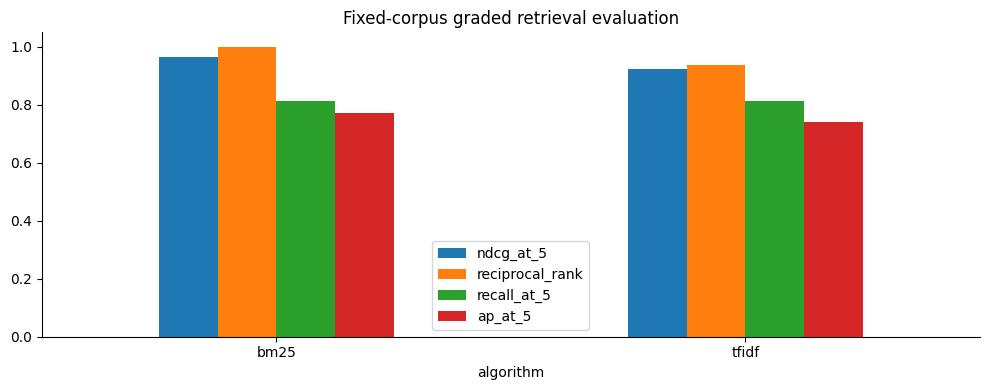

In [3]:
def evaluate(ids,grades,k=5):
    ids=[str(i) for i in ids[:k]];relevant=set(grades)
    gains=[grades.get(i,0) for i in ids]
    dcg=sum((2**gain-1)/math.log2(rank+2) for rank,gain in enumerate(gains))
    ideal=sum((2**gain-1)/math.log2(rank+2) for rank,gain in enumerate(sorted(grades.values(),reverse=True)[:k]))
    rr=next((1/(rank+1) for rank,i in enumerate(ids) if i in relevant),0)
    hits=0;precision_sum=0
    for rank,i in enumerate(ids,1):
        if i in relevant:hits+=1;precision_sum+=hits/rank
    return {'ndcg_at_5':dcg/ideal if ideal else 0,'reciprocal_rank':rr,
            'recall_at_5':hits/len(relevant),'ap_at_5':precision_sum/min(len(relevant),k)}
rows=[]
for algorithm in ['bm25','tfidf']:
    for query,grades in judgments.items():
        hits=index.search(query,algorithm);ids=[h['id'] for h in hits]
        rows.append({'algorithm':algorithm,'query':query,'top_result':ids[0] if ids else None,**evaluate(ids,grades)})
results=pd.DataFrame(rows);display(results.round(3))
summary=results.groupby('algorithm').mean(numeric_only=True);display(summary.round(3))
summary.plot.bar(rot=0,ylim=(0,1.05),title='Fixed-corpus graded retrieval evaluation');plt.tight_layout();plt.show()

## Query coverage and autocomplete

Contrast lexical gaps with matched terms. Prefix suggestions use document frequency and do not constitute semantic query understanding.

In [4]:
queries=['web crawling','web crawler','agentic orchestration','multi agent research','zzzxxyy']
coverage=[]
for query in queries:
    hits=index.search(query)
    coverage.append({'query':query,'result_count':len(hits),'top_title':hits[0]['title'] if hits else '<none>'})
display(pd.DataFrame(coverage))
display(pd.DataFrame([{'prefix':prefix,'suggestions':index.suggest(prefix)} for prefix in ['retr','ma','BM','z']]))
print('Next retrieval experiment: evaluate stemming and controlled query expansion on held-out queries, not these same examples.')

Next retrieval experiment: evaluate stemming and controlled query expansion on held-out queries, not these same examples.


,query,result_count,top_title
0,web crawling,1,Building responsible web crawlers
1,web crawler,1,Building responsible web crawlers
2,agentic orchestration,0,<none>
3,multi agent research,1,Multi agent research systems
4,zzzxxyy,0,<none>


,prefix,suggestions
0,retr,"[retrieval, retrieved]"
1,ma,"[machine, maintainability, maps]"
2,BM,[bm25]
3,z,[]


## Crawler extraction without network

Use local HTML fixtures and a temporary store. The actual crawler should remove script/navigation text, deduplicate repeated links and stay within the seed host. No external site is contacted.

In [5]:
import tempfile
from unittest.mock import patch
from app.infrastructure.store import Store
from app.services.crawler import crawl
pages={
 'https://fixture.example/robots.txt':'User-agent: *\nAllow: /',
 'https://fixture.example/':'<html><title>Home</title><nav>Navigation clutter</nav><main>Clean research evidence.</main><script>malicious()</script><a href="/next">Next</a><a href="/next">Duplicate</a><a href="https://elsewhere.example/">Outside</a></html>',
 'https://fixture.example/next':'<html><title>Next</title><main>Second useful document.</main></html>',
}
with tempfile.TemporaryDirectory() as directory:
    store=Store(str(Path(directory)/'crawl.db'))
    with patch('app.services.crawler.validate_url') as validate, patch('app.services.crawler.fetch',side_effect=lambda url:pages[url]), patch('app.services.crawler.time.sleep'):
        from urllib.parse import urlparse
        validate.side_effect=lambda url:urlparse(url)
        outcome=crawl('https://fixture.example/',store,max_pages=5)
    saved=store.documents()
    assert outcome['indexed']==2 and len(saved)==2
    assert all('Navigation clutter' not in d['content'] and 'malicious()' not in d['content'] for d in saved)
    display(pd.DataFrame(saved))
    print(outcome)

{'indexed': 2, 'urls': ['https://fixture.example/', 'https://fixture.example/next'], 'errors': []}


,id,url,title,content
0,1,https://fixture.example/,Home,Home Clean research evidence. Next Duplicate O...
1,2,https://fixture.example/next,Next,Next Second useful document.


## Fail-closed crawling and persistence

A robots disallow should prevent page retrieval. Store updates must replace a matching URL instead of creating duplicate documents.

In [6]:
with tempfile.TemporaryDirectory() as directory:
    store=Store(str(Path(directory)/'store.db'))
    with patch('app.services.crawler.validate_url',side_effect=lambda url:urlparse(url)), patch('app.services.crawler.fetch',return_value='User-agent: *\nDisallow: /') as fetch:
        blocked=crawl('https://fixture.example/',store,max_pages=1)
        assert blocked['indexed']==0 and fetch.call_count==1
    store.add('https://fixture.example/doc','First','Original contents')
    store.add('https://fixture.example/doc','Updated','Replacement contents')
    assert len(store.documents())==1 and store.documents()[0]['title']=='Updated'
    reopened=Store(str(Path(directory)/'store.db'))
    assert len(reopened.documents())==1
    display({'blocked_crawl':blocked,'persisted_documents':len(reopened.documents())})
print('External network, DNS rebinding protection and multi-worker synchronization require separate deployment testing.')

External network, DNS rebinding protection and multi-worker synchronization require separate deployment testing.


{'blocked_crawl': {'indexed': 0,
  'urls': [],
  'errors': [{'url': 'https://fixture.example/',
    'error': 'Disallowed by robots.txt'}]},
 'persisted_documents': 1}

## Operational release audit

Inspect executable release provenance alongside the experiment. Hashes identify application code and dependency locks; they do not establish model quality. Runtime monitoring reports latency/error aggregates, while quality gates require independent evaluation.

In [7]:
from app.ops import release_info
release = release_info()
display({key: release[key] for key in ['project','release_version','application_sha256','dependency_lock_sha256','analysis_lock_sha256']})
assert len(release['application_sha256']) == 64

from app.experiments import run
import tempfile
with tempfile.TemporaryDirectory() as release_directory:
    release_run, run_record = run(release_directory)
    assert release_run['passed']
    display({'configuration_sha256': release_run['configuration_sha256'], 'quality_gates': release_run['gates'], 'metrics': release_run['metrics']})
print('Offline release checks ran without network or provider credits.')

Offline release checks ran without network or provider credits.


{'project': 'lumen-search',
 'release_version': '1.1.0',
 'application_sha256': '0283db2c13a03792fc15cfc1b0a91b48e5df53394fb24a8a8413a0b1cafdd757',
 'dependency_lock_sha256': '14c03395b54bed88c285951fa991705e5e94952c13e735856e92f311b8af0ca4',
 'analysis_lock_sha256': 'ee0097c2510bdcd1b438115db648c03fbead6054d3a1b0f6ac8a3774fbfaebbf'}

{'configuration_sha256': '549e6ae4d30bc65c3fef2198fd7ad00010312bdaa911e66a20d904759d0c5e45',
 'quality_gates': {'unique_urls': True,
  'nonempty_content': True,
  'bm25_mrr_at_least_075': True,
  'tfidf_mrr_at_least_075': True,
  'phrase_order': True},
 'metrics': {'bm25': {'mrr': 1.0, 'recall_at_5': 1.0},
  'tfidf': {'mrr': 1.0, 'recall_at_5': 1.0}}}